In [1]:
import pvlib
import sys

sys.path.append("../")

import lib.pv as pv
from lib.common import sd

In [2]:
# disable python caching system
# read: https://ploomber.io/blog/clean-nbs/
%load_ext autoreload
%autoreload 2

In [3]:
INPUT_DATA = "../sandbox/notebooks/pgvis_data.csv"
INVERTER = "ABB__PVI_3_0_OUTD_S_US__208V_"

# Panel Data #################

# NOTE: cells_in_series is probably wrong
# The right formula would be:
# v_oc / 0.56 (typically the voltage of each cell)
# which would lead to 95 cells

# NOTE: cells_in_series is probably wrong
# The right formula would be:
# v_oc / 0.56 (typically the voltage of each cell)
# which would lead to 95 cells

# NOTE: !! VERY IMPORTANT !!
# The azimuth base is different between pvgis and pvlib
# info about pvgis azimuth: https://re.jrc.ec.europa.eu/pvg_tools/en/#MR
# info about pvlib azimuth: https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.pvsystem.PVSystem.html
m = pv.Module(
    cellType="monoSi",
    # p_max=400,
    v_mp=44.1,
    i_mp=9.08,
    v_oc=53.4,
    i_sc=9.6,
    alpha_sc=0.0005 * 9.6,
    beta_voc=-0.0029 * 53.4,
    gamma_pmp=-0.37,
    cells_in_series=6 * 27,
    surface_tilt=40,
    azimuth=176,
)

location = pvlib.location.Location(
    latitude=50.941, longitude=6.9587, tz="Europe/Berlin", altitude=80
)
location

Location: 
  name: None
  latitude: 50.941
  longitude: 6.9587
  altitude: 80
  tz: Europe/Berlin

In [4]:
df, _, _ = pvlib.iotools.read_pvgis_hourly(INPUT_DATA)
sd(df)

,poa_direct,poa_sky_diffuse,poa_ground_diffuse,solar_elevation,temp_air,wind_speed,Int
time,,,,,,,
2020-01-01 00:10:00+00:00,0.0,0.0,0.0,0.0,1.82,3.10,0
2020-01-01 01:10:00+00:00,0.0,0.0,0.0,0.0,1.46,2.90,0
2020-01-01 02:10:00+00:00,0.0,0.0,0.0,0.0,1.05,2.97,0


In [5]:
df = pv.poa_data_add_iam(
    azimuth=m.azimuth, surface_tilt=m.surface_tilt, location=location, df=df
)
sd(df)

,poa_direct,poa_sky_diffuse,poa_ground_diffuse,solar_elevation,temp_air,wind_speed,Int,aoi,iam,poa_global
time,,,,,,,,,,
2020-01-01 00:10:00+00:00,0.0,0.0,0.0,0.0,1.82,3.10,0,163.822630,0.0,0.0
2020-01-01 01:10:00+00:00,0.0,0.0,0.0,0.0,1.46,2.90,0,152.183814,0.0,0.0
2020-01-01 02:10:00+00:00,0.0,0.0,0.0,0.0,1.05,2.97,0,138.881121,0.0,0.0


In [6]:
df = pv.cell_temp_poa(df)
sd(df)

,poa_direct,poa_sky_diffuse,poa_ground_diffuse,solar_elevation,temp_air,wind_speed,Int,aoi,iam,poa_global,temp_cell
time,,,,,,,,,,,
2020-01-01 00:10:00+00:00,0.0,0.0,0.0,0.0,1.82,3.10,0,163.822630,0.0,0.0,1.82
2020-01-01 01:10:00+00:00,0.0,0.0,0.0,0.0,1.46,2.90,0,152.183814,0.0,0.0,1.46
2020-01-01 02:10:00+00:00,0.0,0.0,0.0,0.0,1.05,2.97,0,138.881121,0.0,0.0,1.05


<Axes: xlabel='time'>

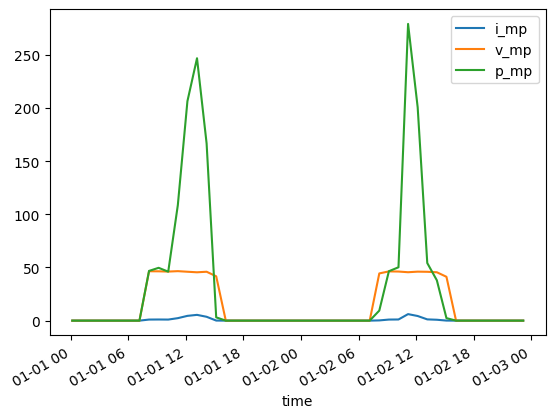

In [7]:
single_module = pv.module_power_cec(m, df)
single_module[:48].plot()

<Axes: xlabel='time'>

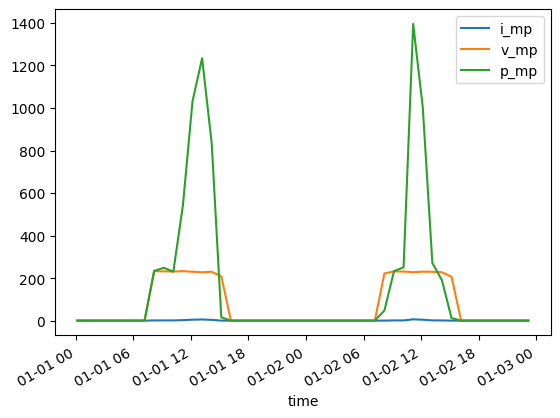

In [8]:
system = pvlib.pvsystem.PVSystem(modules_per_string=5, strings_per_inverter=1)
dc_scaled = system.scale_voltage_current_power(single_module)
dc_scaled[:48].plot()  # type: ignore

In [9]:
cec_inverters = pvlib.pvsystem.retrieve_sam("CecInverter")
inverter = cec_inverters[INVERTER]
inverter

Vac                          208
Pso                    18.166279
Paco                      3000.0
Pdco                  3142.30127
Vdco                       310.0
C0                     -0.000008
C1                     -0.000011
C2                      0.000999
C3                     -0.000287
Pnt                          0.1
Vdcmax                     480.0
Idcmax                 10.136456
Mppt_low                   100.0
Mppt_high                  480.0
CEC_Date                     NaN
CEC_Type     Utility Interactive
Name: ABB__PVI_3_0_OUTD_S_US__208V_, dtype: object

<Axes: xlabel='time'>

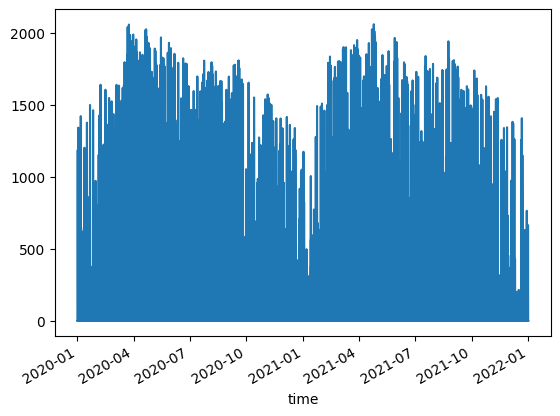

In [10]:
ac_power = pvlib.inverter.sandia(
    v_dc=dc_scaled.v_mp, p_dc=dc_scaled.p_mp, inverter=inverter
)
ac_power.plot()

In [11]:
df = df.assign(p_module=single_module.p_mp, p_dc=dc_scaled.p_mp, p_ac=ac_power)
df

,poa_direct,poa_sky_diffuse,poa_ground_diffuse,solar_elevation,temp_air,wind_speed,Int,aoi,iam,poa_global,temp_cell,p_module,p_dc,p_ac
time,,,,,,,,,,,,,,
2020-01-01 00:10:00+00:00,0.0,0.0,0.0,0.0,1.82,3.10,0,163.822630,0.0,0.0,1.82,0.0,0.0,-0.1
2020-01-01 01:10:00+00:00,0.0,0.0,0.0,0.0,1.46,2.90,0,152.183814,0.0,0.0,1.46,0.0,0.0,-0.1
2020-01-01 02:10:00+00:00,0.0,0.0,0.0,0.0,1.05,2.97,0,138.881121,0.0,0.0,1.05,0.0,0.0,-0.1
2020-01-01 03:10:00+00:00,0.0,0.0,0.0,0.0,0.56,3.17,0,125.171153,0.0,0.0,0.56,0.0,0.0,-0.1
2020-01-01 04:10:00+00:00,0.0,0.0,0.0,0.0,0.20,3.10,0,111.379529,0.0,0.0,0.20,0.0,0.0,-0.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-12-31 19:10:00+00:00,0.0,0.0,0.0,0.0,12.38,4.41,0,118.332060,0.0,0.0,12.38,0.0,0.0,-0.1
2021-12-31 20:10:00+00:00,0.0,0.0,0.0,0.0,12.26,3.66,0,132.108734,0.0,0.0,12.26,0.0,0.0,-0.1
2021-12-31 21:10:00+00:00,0.0,0.0,0.0,0.0,12.14,3.72,0,145.682469,0.0,0.0,12.14,0.0,0.0,-0.1
